In [1]:
import numpy,pandas,json,sys
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess #type: ignore

sys.path.append("../../code/utility")
from load_data import load_cadmium,split_data_by_site,load_carbon

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600
# pyplot.rcParams.update({
#     "figure.facecolor":  (0.0, 0.0, 0.0, 0.0),
#     "axes.facecolor":    (0.0, 0.0, 0.0, 0.0),
#     "savefig.facecolor": (0.0, 0.0, 0.0, 0.0),
# })

# Age vs δ<sup>114</sup>Cd

In [2]:
# Load in d114Cd data
data_directory = "../../data/"
d114cd_data = load_cadmium(data_directory)
svalbard_cd_data,arctic_cd_data,northsea_cd_data,kheu_cd_data = split_data_by_site(d114cd_data)

# Load in GPs
d114cd_gp = GaussianProcess().fromJSON(data_directory+"/output/d114cd_gp.json")

# Load in prior_results
with open(data_directory+"/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)

# Load in posterior_results
with open(data_directory+"/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel(data_directory+"output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_posterior_metrics.xlsx")

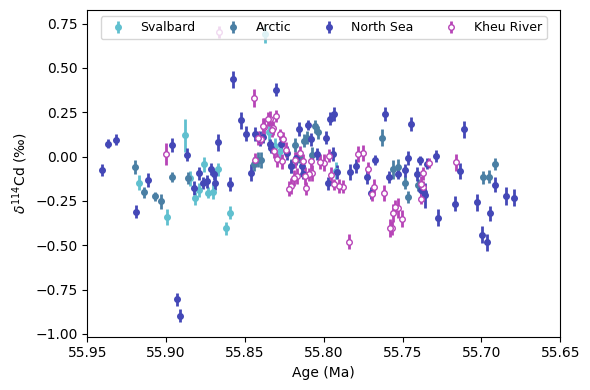

In [3]:
# Plot Data
figure,axis = pyplot.subplots(nrows=1,sharex=True,figsize=(6,4))
axes= [axis]

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}

handle_0 = axes[0].errorbar(svalbard_cd_data["Age model"],svalbard_cd_data["δ114Cd(‰)"],yerr=svalbard_cd_data["δ114Cd (2σ)"],color="#60c0cf",ecolor="#60c0cf",**common_attributes)
handle_1 = axes[0].errorbar(arctic_cd_data["Age model"],arctic_cd_data["δ114Cd(‰)"],yerr=arctic_cd_data["δ114Cd (2σ)"],color="#4a7fa4",ecolor="#4a7fa4",**common_attributes)
handle_2 = axes[0].errorbar(northsea_cd_data["Age model"],northsea_cd_data["δ114Cd(‰)"],yerr=northsea_cd_data["δ114Cd (2σ)"],color="#4448b7",ecolor="#4448b7",**common_attributes)
handle_3 = axes[0].errorbar(kheu_cd_data["Age model"],kheu_cd_data["δ114Cd(‰)"],yerr=kheu_cd_data["δ114Cd (2σ)"],markerfacecolor="#ffffff",markeredgecolor="#b744b7",ecolor="#b744b7",**common_attributes)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",fontsize=9)

axes[0].set_xlim((55.95,55.65))

# Add labels
axes[0].set_xlabel("Age (Ma)")
axes[0].set_ylabel("$\\delta^{114}$Cd (‰)")


figure.tight_layout()
pyplot.show()
# figure.savefig("./figures/cadmium_data.png",transparent=True)


# With GP

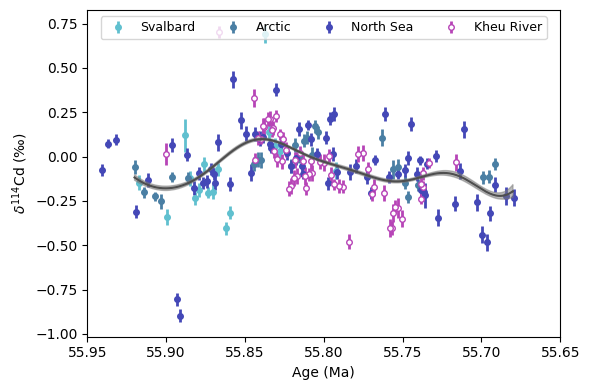

In [4]:
figure

d114cd_gp.plotMean(group=-1,color="#4e4e4e",axis=axes[0])
d114cd_gp.plotArea(group=-1,color="#777777",alpha=0.5,set_axes=False,axis=axes[0])


figure.tight_layout()
# figure.savefig("./figures/cadmium_data_gp.png",transparent=True)

figure